# Caractériser un système

In [80]:
# import
import matplotlib.pyplot as plt; from scipy.io import wavfile
%run ./init.py

## Réponse impulsionnelle d'une salle

Connaître la réponse impulsionnelle d'un système permet de le caractériser complètement.  
Utiliser directement une impulsion est rarement envisageable (e.g. rupture membrane HP).  
On utilise souvent un sweep/chirp: un signal continu qui passe par toutes les fréquences. 

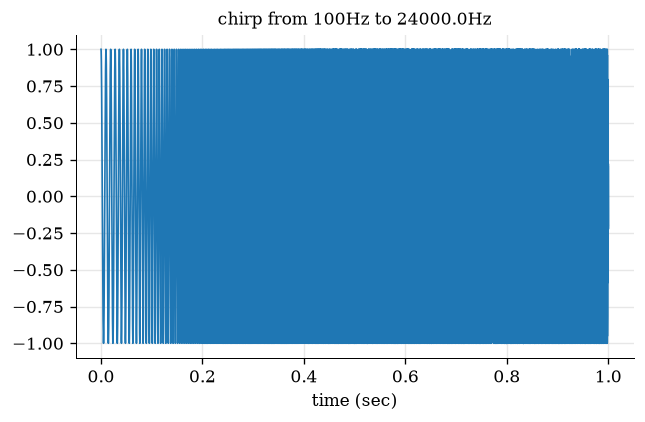

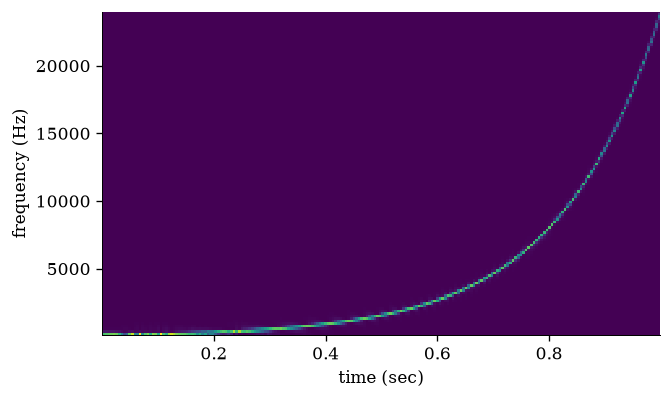

In [81]:
# init locals
duration_in_sec = 1
f_start = 100; f_stop = fs/2

# define time vector
t = np.arange(0, duration_in_sec*fs)/fs

# create chirp
x = scipy.signal.chirp(t, f_start, t[-1], f_stop, method = 'log')

# # create chirp (manual)
# f = f_start * (f_stop/f_start) ** (t / t[-1] )
# x = np.sin(2*math.pi*np.multiply(f, t))

# plot signal
plt.plot(t, x)
# plt.xlim([0, 0.1])
plt.title(f'chirp from {f_start}Hz to {f_stop}Hz'); plt.xlabel('time (sec)'); plt.show()

# playback
playsound(x, fs)

# plot spectrogram
f, t, Sxx = scipy.signal.spectrogram(x, fs)
plt.pcolormesh(t, f, Sxx)
plt.ylabel('frequency (Hz)'); plt.xlabel('time (sec)')
# plt.yscale('log')
plt.ylim([f_start, f_stop])
plt.show()

Pour obtenir la réponse impulsionnelle d'une salle, on enregistre ce sweep dans une salle et on **déconvolue** cet enregistrement avec le sweep original.  
L'opération est généralement réalisée dans le domaine fréquentiel. 

/Users/pyrus/Teaching/ens_louis_lumiere/signal_processing/td_dpq/jupyterlite_scripts/content/init.py:17: WavFileWarning: Chunk (non-data) not understood, skipping it.
  fs, audio = scipy.io.wavfile.read(filepath)


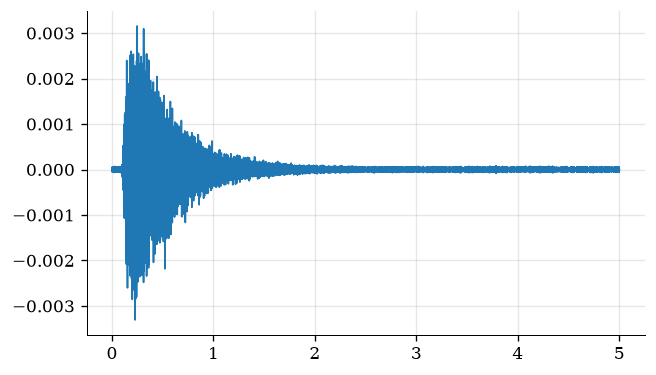

In [82]:
# load reference sweep
sweep_ref, fs = wavread('assets/sweep_ref.wav')

# load measured sweep
sweep_meas, fs = wavread('assets/sweep_meas.wav')

# playback
playsound(sweep_ref, fs)
playsound(sweep_meas, fs)

# band pass filter (remove frequencies outside of sweep)
f_low = 50; f_high = 18000
# [b_bp, a_bp] = butter(6, [f_low, f_high] / (fs/2), 'bandpass');
# sweep = filtfilt(b_bp, a_bp, sweep);
b, a = scipy.signal.iirfilter(N=6, Wn=[f_low, f_high], fs=fs, btype='bandpass', ftype='butter')
sweep_meas = scipy.signal.filtfilt(b, a, sweep_meas)

# fft
n = len(sweep_meas)
sweep_meas_fft = np.fft.rfft(sweep_meas, n)
sweep_ref_fft = np.fft.rfft(sweep_ref, n)
# freqs = np.fft.rfftfreq(n, 1/fs)

# deconvolution
ir_fft = sweep_meas_fft / sweep_ref_fft

# back to time domain 
ir = np.fft.irfft(ir_fft, n)

# crop
threshold = 0.03 * np.max(np.abs(ir))
duration = 5 # in sec
id_start = next(x[0] for x in enumerate(ir) if x[1] > threshold) - int(0.1 * fs)
# id_stop = len(ir) - next(x[0] for x in enumerate(ir[::-1]) if x[1] > threshold)
id_stop = id_start + duration * fs
ir = ir[id_start:id_stop]

# play
playsound(ir, fs)

# plot
t = np.arange(0, len(ir)) / fs
plt.plot(t, ir)
plt.show()

## EQ haut-parleur / casque

On utilise la même méthode pour égaliser la réponse en fréquence d'un HP (la rendre "plate").  
Dans ce cas, l'inverse de la réponse en fréquence (mesurée avec le sweep) est utilisée pour pré-filtrer les sons joués sur ce HP.